# 02 — Quality control (Bogotá)

Applies the QC conventions used in the group's prior work
(Casallas et al. 2022, *Spatio-temporal analysis of PM2.5 and policies in Northwestern
South America*, `Articles/Articles_mios/Tendencies_PM2p5.pdf`, sec. 2.1.1):

1. **Physical range checks** — implausible values (e.g. negative concentrations,
   RH > 100%) set to NaN.
2. **Chauvenet's criterion** (per station, per variable) to flag statistical outliers.
3. **Completeness filtering** — station-years are only used downstream if they meet the
   paper's >=75% valid-day threshold.
4. Build a **city-network daily series** (mean across qualifying stations each day),
   matching the "average of background stations" convention from the paper.


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("/path/to/project")
sys.path.insert(0, str(PROJECT_ROOT / "Scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from common.qc import (
    apply_physical_range_checks,
    flag_chauvenet_outliers,
    completeness_by_station_year,
    select_stations_years,
)

IN_DIR = OUT_DIR = PROJECT_ROOT / "Data" / "processed" / "colombia" / "bogota"
FIG_DIR = PROJECT_ROOT / "Scripts" / "colombia" / "bogota" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

raw = pd.read_parquet(IN_DIR / "bogota_raw_merged.parquet")
value_cols = [c for c in raw.columns if c not in ("station", "date")]
print(raw.shape)
raw.head()


(92192, 13)


,station,date,pm25,pm10,no2,o3,wind_speed,wind_dir,temp_2m,temp_10m,rh_2m,rh_10m,pressure
0,BOGOTA RURAL - MOCHUELO,2010-01-04,NaN,59.37,47.69,59.85,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,BOGOTA RURAL - MOCHUELO,2010-01-06,NaN,68.72,42.61,63.57,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,BOGOTA RURAL - MOCHUELO,2010-01-10,NaN,72.56,54.83,66.14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,BOGOTA RURAL - MOCHUELO,2010-01-14,NaN,69.33,57.20,67.24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,BOGOTA RURAL - MOCHUELO,2010-01-17,NaN,64.02,48.62,68.62,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Station-name check

A few names look like the same physical site reported under different labels across
files/years (e.g. Fontibón variants). We don't auto-merge these — flagging only, since
merging the wrong pair would silently mix two different stations.


In [2]:
print(sorted(raw['station'].unique()))


['BOGOTA RURAL - MOCHUELO', 'BOLIVIA', 'BOSA', 'CARVAJAL - SEVILLANA', 'CENTRO DE ALTO RENDIMIENTO', 'CHICO LAGO (STO TOMAS)', 'CIUDAD BOLÍVAR', 'COLINA', 'EL JAZMÍN', 'Fontibon', 'GUAYMARAL', 'KENNEDY', 'LAS FERIAS', 'MINAMBIENTE', 'MOCHUELO - COLEGIO', 'MÓVIL 7MA', 'MÓVIL FONTIBÓN', 'PUENTE ARANDA', 'P_CAMI - FONTIBÓN', 'SAN CRISTOBAL', 'SUBA', 'TUNAL', 'USAQUEN', 'USME']


## 1. Physical range checks

In [3]:
clean = apply_physical_range_checks(raw)


[range check] pm10: 1 values outside [0.0, 1500.0] -> NaN
[range check] rh_2m: 2 values outside [0.0, 100.0] -> NaN


## 2. Chauvenet's criterion (per station, per variable)

In [4]:
clean = flag_chauvenet_outliers(clean, value_cols=value_cols, group_col='station')
outlier_cols = [c for c in clean.columns if c.endswith('_outlier')]
clean[outlier_cols].sum().sort_values(ascending=False)


[Chauvenet] pm25: flagged 169 outliers
[Chauvenet] pm10: flagged 145 outliers
[Chauvenet] no2: flagged 113 outliers
[Chauvenet] o3: flagged 256 outliers
[Chauvenet] wind_speed: flagged 63 outliers
[Chauvenet] wind_dir: flagged 31 outliers
[Chauvenet] temp_2m: flagged 52 outliers
[Chauvenet] temp_10m: flagged 5 outliers
[Chauvenet] rh_2m: flagged 60 outliers
[Chauvenet] rh_10m: flagged 2 outliers


o3_outlier            256
pm25_outlier          169
pm10_outlier          145
no2_outlier           113
wind_speed_outlier     63
rh_2m_outlier          60
temp_2m_outlier        52
wind_dir_outlier       31
temp_10m_outlier        5
rh_10m_outlier          2
pressure_outlier        0
dtype: int64

## 3. Completeness by station-year (target variable: PM2.5)

In [5]:
completeness = completeness_by_station_year(clean, value_col='pm25')
completeness.sort_values(['station', 'year']).head(20)


,station,year,n_valid_days,days_in_year,completeness
0,BOGOTA RURAL - MOCHUELO,2017,281,365,0.769863
1,BOGOTA RURAL - MOCHUELO,2018,294,365,0.805479
2,BOGOTA RURAL - MOCHUELO,2019,343,365,0.939726
3,BOGOTA RURAL - MOCHUELO,2020,360,366,0.983607
4,BOGOTA RURAL - MOCHUELO,2021,350,365,0.958904
5,BOGOTA RURAL - MOCHUELO,2022,346,365,0.947945
6,BOGOTA RURAL - MOCHUELO,2023,346,365,0.947945
7,BOGOTA RURAL - MOCHUELO,2024,327,366,0.893443
8,BOGOTA RURAL - MOCHUELO,2025,343,365,0.939726
9,BOGOTA RURAL - MOCHUELO,2026,228,365,0.624658


In [6]:
qualifying = select_stations_years(completeness, threshold=0.75)
print(f"{len(qualifying)} / {len(completeness)} station-years meet the >=75% completeness threshold")
qualifying.groupby('station')['year'].apply(list)


166 / 212 station-years meet the >=75% completeness threshold


station
BOGOTA RURAL - MOCHUELO       [2017, 2018, 2019, 2020, 2021, 2022, 2023, 202...
BOLIVIA                                                [2021, 2022, 2023, 2025]
CARVAJAL - SEVILLANA           [2014, 2015, 2017, 2018, 2019, 2020, 2021, 2024]
CENTRO DE ALTO RENDIMIENTO    [2014, 2015, 2016, 2018, 2019, 2020, 2021, 202...
CIUDAD BOLÍVAR                                   [2021, 2022, 2023, 2024, 2025]
COLINA                                                 [2021, 2022, 2023, 2024]
EL JAZMÍN                                        [2021, 2022, 2023, 2024, 2025]
GUAYMARAL                     [2015, 2016, 2017, 2018, 2019, 2020, 2021, 202...
KENNEDY                       [2014, 2015, 2016, 2017, 2018, 2019, 2020, 202...
LAS FERIAS                    [2014, 2015, 2016, 2017, 2018, 2019, 2020, 202...
MINAMBIENTE                   [2015, 2016, 2017, 2018, 2019, 2020, 2021, 202...
MOCHUELO - COLEGIO                                                 [2024, 2025]
MÓVIL 7MA                       

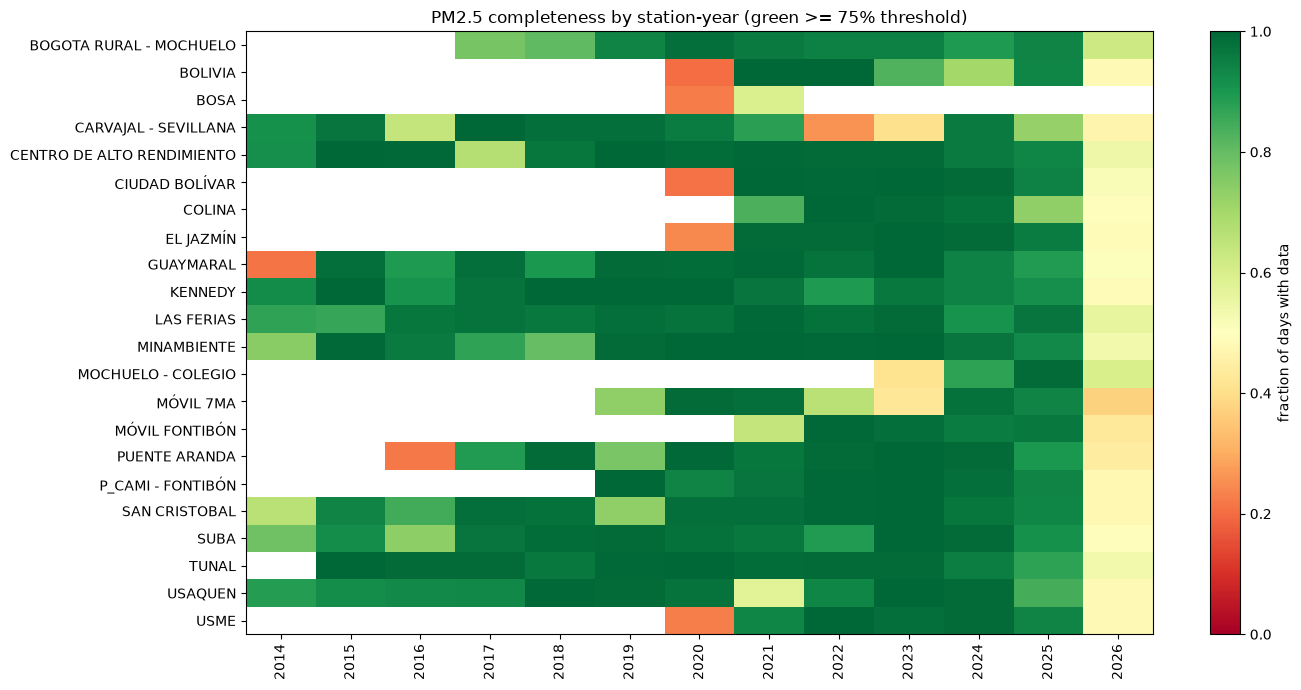

In [7]:
pivot = completeness.pivot(index='station', columns='year', values='completeness')
fig, ax = plt.subplots(figsize=(14, 7))
im = ax.imshow(pivot.values, aspect='auto', cmap='RdYlGn', vmin=0, vmax=1)
ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns, rotation=90)
ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index)
ax.set_title('PM2.5 completeness by station-year (green >= 75% threshold)')
fig.colorbar(im, ax=ax, label='fraction of days with data')
fig.tight_layout()
fig.savefig(FIG_DIR / 'pm25_completeness_heatmap.png', dpi=150)
plt.show()


## 4. City-network daily series

Following the Casallas convention, the city-representative daily value for each variable
is the mean across stations that qualify (>=75% completeness) for PM2.5 in that year.
Using the PM2.5-qualifying station set for all variables keeps the network consistent
day to day; met variables from the same qualifying stations are averaged the same way.


In [8]:
qualifying_keys = set(zip(qualifying['station'], qualifying['year']))
clean['year'] = clean['date'].dt.year
clean['is_qualifying'] = clean.apply(lambda r: (r['station'], r['year']) in qualifying_keys, axis=1)

qc_stations = clean[clean['is_qualifying']].copy()
print("Station-days retained after completeness filtering:", len(qc_stations))

network_daily = (
    qc_stations
    .groupby('date')[value_cols]
    .mean()
    .reset_index()
    .sort_values('date')
)
network_daily.head()


Station-days retained after completeness filtering: 60066


,date,pm25,pm10,no2,o3,wind_speed,wind_dir,temp_2m,temp_10m,rh_2m,rh_10m,pressure
0,2014-01-01,13.528329,37.976852,14.294409,16.360083,2.371065,150.214258,15.286343,NaN,53.705231,NaN,563.440937
1,2014-01-02,15.158107,43.974937,11.928801,12.579749,1.867305,189.721743,14.324294,NaN,62.478449,NaN,562.737743
2,2014-01-03,12.828891,43.317340,11.893986,9.409742,2.095023,140.945507,14.716088,NaN,62.847083,NaN,562.995208
3,2014-01-04,13.096492,39.501157,10.957708,11.156179,2.164120,129.193873,13.992130,NaN,63.232569,NaN,563.493021
4,2014-01-05,14.356369,37.445602,11.736037,13.893389,1.670255,142.051679,14.223727,NaN,68.230046,NaN,563.577465


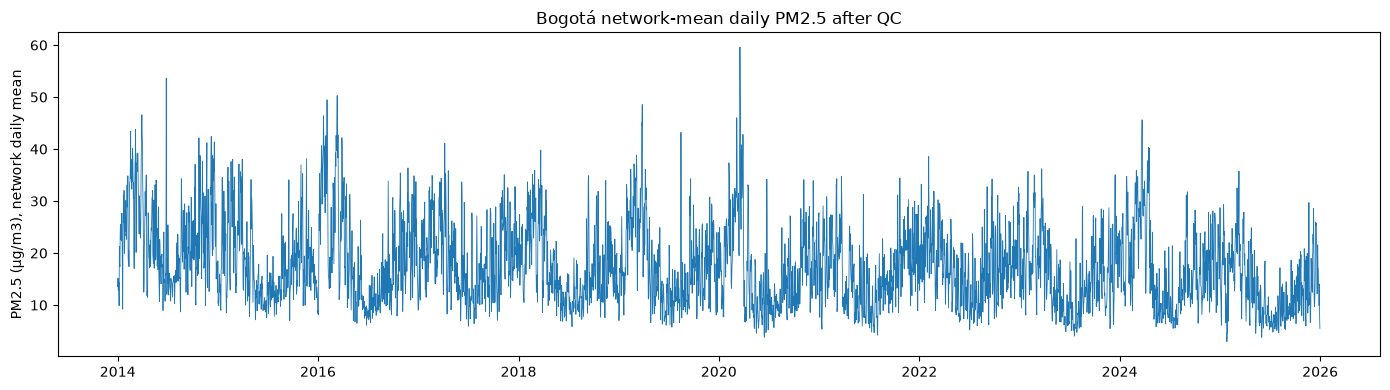

In [9]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(network_daily['date'], network_daily['pm25'], lw=0.6)
ax.set_ylabel('PM2.5 (µg/m3), network daily mean')
ax.set_title('Bogotá network-mean daily PM2.5 after QC')
fig.tight_layout()
fig.savefig(FIG_DIR / 'pm25_network_daily_timeseries.png', dpi=150)
plt.show()


## Sanity check against Casallas et al. (2022)

The paper reports Bogotá annual PM2.5 means in the ~15-25 µg/m3 range with a March peak
and a JJA (Jun-Aug) minimum, and a declining annual trend of about -0.8 to -1.7 µg/m3/yr
over 2014-2019.


date
2014-12-31    23.243920
2015-12-31    17.695043
2016-12-31    19.477315
2017-12-31    18.955127
2018-12-31    17.167304
2019-12-31    17.901034
2020-12-31    17.156037
2021-12-31    15.951465
2022-12-31    17.071071
2023-12-31    15.316937
2024-12-31    17.389322
2025-12-31    13.195181
Freq: YE-DEC, Name: pm25, dtype: float64


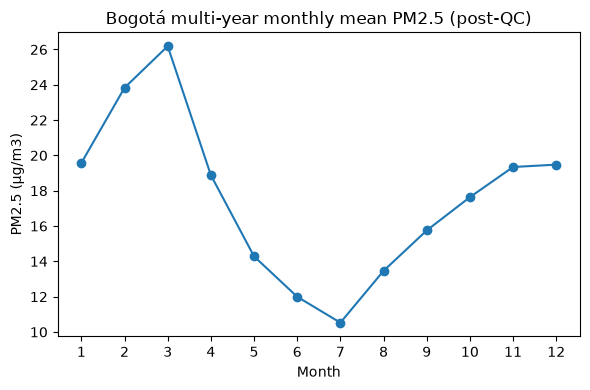

In [10]:
annual_mean = network_daily.set_index('date')['pm25'].resample('YE').mean()
print(annual_mean)

monthly_mean = network_daily.set_index('date')['pm25'].groupby(network_daily.set_index('date').index.month).mean()
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(monthly_mean.index, monthly_mean.values, marker='o')
ax.set_xticks(range(1, 13))
ax.set_xlabel('Month'); ax.set_ylabel('PM2.5 (µg/m3)')
ax.set_title('Bogotá multi-year monthly mean PM2.5 (post-QC)')
fig.tight_layout()
fig.savefig(FIG_DIR / 'pm25_monthly_climatology.png', dpi=150)
plt.show()


## Save cleaned datasets

In [11]:
station_out = qc_stations.drop(columns=[c for c in qc_stations.columns if c.endswith('_outlier')] + ['year', 'is_qualifying'])
station_path = OUT_DIR / "bogota_stations_daily_clean.parquet"
station_out.to_parquet(station_path, index=False)

network_path = OUT_DIR / "bogota_network_daily_clean.parquet"
network_daily.to_parquet(network_path, index=False)

completeness_path = OUT_DIR / "bogota_pm25_completeness_by_station_year.csv"
completeness.to_csv(completeness_path, index=False)

print("Saved:")
print(" ", station_path, station_out.shape)
print(" ", network_path, network_daily.shape)
print(" ", completeness_path)


Saved:
  /path/to/project/Data/processed/colombia/bogota/bogota_stations_daily_clean.parquet (60066, 13)
  /path/to/project/Data/processed/colombia/bogota/bogota_network_daily_clean.parquet (4383, 12)
  /path/to/project/Data/processed/colombia/bogota/bogota_pm25_completeness_by_station_year.csv
